In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN





In [2]:

stocks_sect = pd.read_parquet("data_processed/stocks_sect.parquet")
stocks_sect.head()
print(stocks_sect.shape)
stocks_sect.columns



(9867430, 21)


Index(['Date', 'Weekday', 'Open', 'High', 'Low', 'Close', 'Adj Close',
       'Volume', 'Symbol', 'Volatility', 'ticker', 'Sector', 'Return',
       'SectorVolume', 'Weight', 'RollingVol20', 'WeightedVol20',
       'RollingVol60', 'WeightedVol60', 'RollingVol120', 'WeightedVol120'],
      dtype='object')

In [3]:
CFG = {
    "chapter": 4,
    "use_assets": "stocks_only",            
    "market_proxy": "SPY",
    "date_col": "Date",
    "sector_col": "Sector",
    "return_col": "Return",
    "weight_col": "Weight",                   
    "spy_price_col_preference": "Adj Close",  
    "regime_method": "drawdown",
    "bear_dd_threshold": -0.20,               
    "neutral_dd_threshold": -0.05            
}

CFG


{'chapter': 4,
 'use_assets': 'stocks_only',
 'market_proxy': 'SPY',
 'date_col': 'Date',
 'sector_col': 'Sector',
 'return_col': 'Return',
 'weight_col': 'Weight',
 'spy_price_col_preference': 'Adj Close',
 'regime_method': 'drawdown',
 'bear_dd_threshold': -0.2,
 'neutral_dd_threshold': -0.05}

In [4]:
# Date to datetime
stocks_sect[CFG["date_col"]] = pd.to_datetime(stocks_sect[CFG["date_col"]])

# Ensure numeric types for core columns
for c in [CFG["return_col"], CFG["weight_col"]]:
    stocks_sect[c] = pd.to_numeric(stocks_sect[c], errors="coerce")

# Quick missingness check on the columns we will use
core_cols = [CFG["date_col"], CFG["sector_col"], CFG["return_col"], CFG["weight_col"]]
stocks_sect[core_cols].isna().mean().sort_values(ascending=False)


Return    0.000339
Date      0.000000
Sector    0.000000
Weight    0.000000
dtype: float64

In [5]:
# Basic stats
print("Return stats:")
display(stocks_sect[CFG["return_col"]].describe())

print("\nWeight stats:")
display(stocks_sect[CFG["weight_col"]].describe())

# Check weight sums: for each (Date, Sector), sum of weights should be ~1
w_sum = (
    stocks_sect
    .groupby([CFG["date_col"], CFG["sector_col"]])[CFG["weight_col"]]
    .sum()
)

print("Weight sum (Date,Sector) - summary:")
display(w_sum.describe())

# Show worst offenders (largest deviations from 1)
deviation = (w_sum - 1.0).abs().sort_values(ascending=False)
deviation.head(10)


Return stats:


count    9.864084e+06
mean     4.745029e-04
std      3.701648e-02
min     -5.000000e-01
25%     -1.013517e-02
50%      0.000000e+00
75%      1.031089e-02
max      5.000000e-01
Name: Return, dtype: float64


Weight stats:


count    9.867430e+06
mean     4.278520e-03
std      1.723225e-02
min      3.627926e-33
25%      7.715072e-05
50%      4.594027e-04
75%      2.473579e-03
max      9.567349e-01
Name: Weight, dtype: float64

Weight sum (Date,Sector) - summary:


count    4.221800e+04
mean     1.000000e+00
std      4.713976e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: Weight, dtype: float64

Date        Sector            
2006-05-15  Consumer Defensive    2.220446e-16
2008-04-10  Industrials           2.220446e-16
2005-11-03  Healthcare            2.220446e-16
2008-04-07  Industrials           2.220446e-16
2014-01-16  Consumer Cyclical     2.220446e-16
2009-05-05  Basic Materials       2.220446e-16
2012-11-07  Industrials           2.220446e-16
2011-06-30  Industrials           2.220446e-16
2005-03-14  Energy                2.220446e-16
2008-04-09  Basic Materials       2.220446e-16
Name: Weight, dtype: float64

# 3. Import SPY Data


In [6]:
spy = pd.read_csv("/Users/chedliabdennebi/Desktop/ADA/projet/spy.csv")

print("SPY shape:", spy.shape)
display(spy.head())
spy.columns


SPY shape: (6845, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,1993-01-29,43.96875,43.96875,43.75000,43.93750,25.029377,1003200
1,1993-02-01,43.96875,44.25000,43.96875,44.25000,25.207405,480500
2,1993-02-02,44.21875,44.37500,44.12500,44.34375,25.260784,201300
3,1993-02-03,44.40625,44.84375,44.37500,44.81250,25.527805,529400
4,1993-02-04,44.96875,45.09375,44.46875,45.00000,25.634638,531500


Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

In [7]:
spy["Date"] = pd.to_datetime(spy["Date"])

spy = (
    spy[["Date", "Adj Close"]]
    .rename(columns={"Adj Close": "SPY_Price"})
    .sort_values("Date")
    .reset_index(drop=True)
)

print("SPY cleaned shape:", spy.shape)
display(spy.head())
display(spy.tail())


SPY cleaned shape: (6845, 2)


,Date,SPY_Price
0,1993-01-29,25.029377
1,1993-02-01,25.207405
2,1993-02-02,25.260784
3,1993-02-03,25.527805
4,1993-02-04,25.634638


,Date,SPY_Price
6840,2020-03-30,249.015793
6841,2020-03-31,245.304153
6842,2020-04-01,234.264252
6843,2020-04-02,239.669968
6844,2020-04-03,236.205734


In [8]:
spy["SPY_Return"] = np.log(spy["SPY_Price"]).diff()

display(spy.head(10))


,Date,SPY_Price,SPY_Return
0,1993-01-29,25.029377,NaN
1,1993-02-01,25.207405,0.007088
2,1993-02-02,25.260784,0.002115
3,1993-02-03,25.527805,0.010515
4,1993-02-04,25.634638,0.004176
5,1993-02-05,25.616837,-0.000695
6,1993-02-08,25.616837,0.000000
7,1993-02-09,25.438820,-0.006973
8,1993-02-10,25.474417,0.001398
9,1993-02-11,25.599033,0.004880


In [9]:
spy["SPY_Index"] = 100 * np.exp(spy["SPY_Return"].fillna(0).cumsum())

display(spy.head())


,Date,SPY_Price,SPY_Return,SPY_Index
0,1993-01-29,25.029377,NaN,100.000000
1,1993-02-01,25.207405,0.007088,100.711276
2,1993-02-02,25.260784,0.002115,100.924542
3,1993-02-03,25.527805,0.010515,101.991372
4,1993-02-04,25.634638,0.004176,102.418202


In [10]:
spy["Running_Max"] = spy["SPY_Index"].cummax()
spy["Drawdown"] = (spy["SPY_Index"] / spy["Running_Max"]) - 1

display(spy[["Date", "SPY_Index", "Running_Max", "Drawdown"]].head(10))
display(spy[["Date", "SPY_Index", "Running_Max", "Drawdown"]].tail(10))


,Date,SPY_Index,Running_Max,Drawdown
0,1993-01-29,100.000000,100.000000,0.000000
1,1993-02-01,100.711276,100.711276,0.000000
2,1993-02-02,100.924542,100.924542,0.000000
3,1993-02-03,101.991372,101.991372,0.000000
4,1993-02-04,102.418202,102.418202,0.000000
5,1993-02-05,102.347082,102.418202,-0.000694
6,1993-02-08,102.347082,102.418202,-0.000694
7,1993-02-09,101.635850,102.418202,-0.007639
8,1993-02-10,101.778071,102.418202,-0.006250
9,1993-02-11,102.275950,102.418202,-0.001389


,Date,SPY_Index,Running_Max,Drawdown
6835,2020-03-23,847.741812,1278.978298,-0.337173
6836,2020-03-24,924.549932,1278.978298,-0.277118
6837,2020-03-25,938.390664,1278.978298,-0.266297
6838,2020-03-26,993.183210,1278.978298,-0.223456
6839,2020-03-27,963.600480,1278.978298,-0.246586
6840,2020-03-30,994.894092,1278.978298,-0.222118
6841,2020-03-31,980.064957,1278.978298,-0.233713
6842,2020-04-01,935.957183,1278.978298,-0.268199
6843,2020-04-02,957.554669,1278.978298,-0.251313
6844,2020-04-03,943.713997,1278.978298,-0.262134


# 4. Define Regimes

In [11]:
def label_regime(drawdown, bear_th=-0.20, neutral_th=-0.05):
    if drawdown <= bear_th:
        return "Bear"
    elif drawdown <= neutral_th:
        return "Neutral"
    else:
        return "Bull"

spy["Regime"] = spy["Drawdown"].apply(label_regime)

spy[["Date", "Drawdown", "Regime"]].head(10)


,Date,Drawdown,Regime
0,1993-01-29,0.000000,Bull
1,1993-02-01,0.000000,Bull
2,1993-02-02,0.000000,Bull
3,1993-02-03,0.000000,Bull
4,1993-02-04,0.000000,Bull
5,1993-02-05,-0.000694,Bull
6,1993-02-08,-0.000694,Bull
7,1993-02-09,-0.007639,Bull
8,1993-02-10,-0.006250,Bull
9,1993-02-11,-0.001389,Bull


In [12]:
spy["Regime"].value_counts(normalize=True).round(3)


Regime
Bull       0.531
Neutral    0.266
Bear       0.203
Name: proportion, dtype: float64

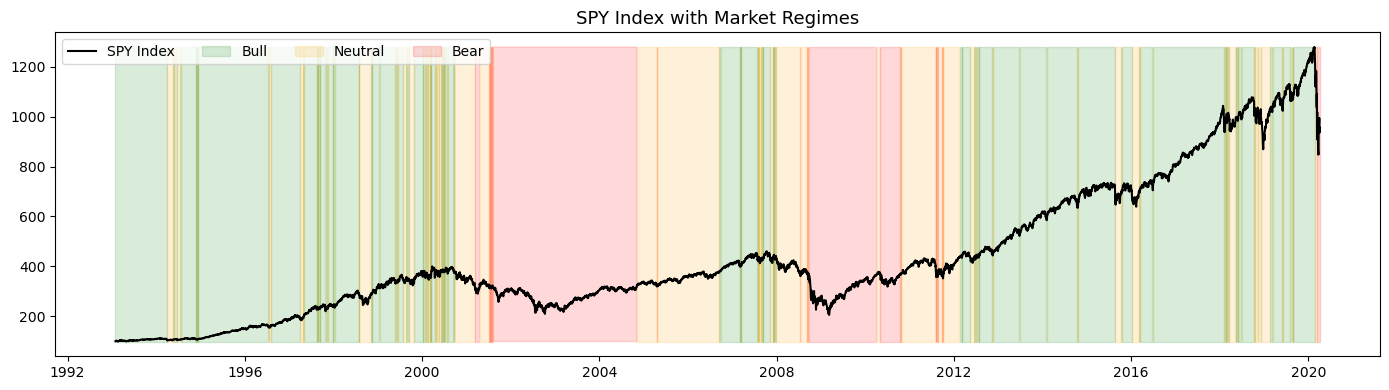

In [69]:
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(14, 4))

# 1. Plot SPY index as a clean line
plt.plot(
    spy["Date"],
    spy["SPY_Index"],
    color="black",
    linewidth=1.5,
    label="SPY Index"
)

# 2. Regime colors
regime_colors = {
    "Bull": "green",
    "Neutral": "orange",
    "Bear": "red"
}

# 3. Shade background by regime (continuous blocks)
for regime, color in regime_colors.items():
    mask = spy["Regime"] == regime
    
    plt.fill_between(
        spy["Date"],
        spy["SPY_Index"].min(),
        spy["SPY_Index"].max(),
        where=mask,
        color=color,
        alpha=0.15,
        label=regime
    )

# 4. Formatting
plt.title("SPY Index with Market Regimes", fontsize=13)
plt.legend(loc="upper left", ncol=4)
plt.tight_layout()
plt.show()


# 5. Compute Daily Sector returns

In [15]:
import numpy as np
import pandas as pd

core = stocks_sect[[CFG["date_col"], CFG["sector_col"], CFG["return_col"], CFG["weight_col"]]].copy()
core = core.dropna(subset=[CFG["return_col"]])  # only Return had tiny missingness

# weighted sector return per (Date, Sector)
sector_daily = (
    core.groupby([CFG["date_col"], CFG["sector_col"]], as_index=False)
        .apply(lambda g: pd.Series({
            "SectorReturn": np.sum(g[CFG["return_col"]] * g[CFG["weight_col"]]),
            "WeightSum": g[CFG["weight_col"]].sum(),
            "N": len(g)
        }))
        .reset_index(drop=True)
)

sector_daily.head(), sector_daily.shape


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_72829/1360699461.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


(        Date                  Sector  SectorReturn  WeightSum      N
 0 2005-01-04         Basic Materials     -0.025943        1.0   94.0
 1 2005-01-04  Communication Services     -0.018059        1.0   60.0
 2 2005-01-04       Consumer Cyclical     -0.011764        1.0  198.0
 3 2005-01-04      Consumer Defensive     -0.017587        1.0   87.0
 4 2005-01-04                  Energy     -0.010518        1.0   84.0,
 (42207, 5))

In [16]:
sector_daily.duplicated([CFG["date_col"], CFG["sector_col"]]).sum()


np.int64(0)

In [17]:
sector_daily["SectorReturn"].describe()


count    42207.000000
mean         0.001296
std          0.021030
min         -0.295946
25%         -0.007147
50%          0.001540
75%          0.009703
max          0.285009
Name: SectorReturn, dtype: float64

In [18]:
sector_daily["WeightSum"].describe()


count    42207.000000
mean         0.999332
std          0.010052
min          0.344785
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: WeightSum, dtype: float64

In [19]:
sector_daily[(sector_daily["WeightSum"] < 0.95) | (sector_daily["WeightSum"] > 1.05)].head(20)


,Date,Sector,SectorReturn,WeightSum,N
132,2005-01-21,Basic Materials,0.023790,0.791154,94.0
191,2005-01-28,Energy,-0.003777,0.911257,84.0
292,2005-02-10,Healthcare,0.000002,0.931820,201.0
348,2005-02-17,Industrials,-0.005887,0.880305,243.0
700,2005-04-06,Industrials,0.003110,0.944283,246.0
929,2005-05-05,Financial Services,-0.002042,0.815384,530.0
1097,2005-05-26,Real Estate,0.003607,0.817713,89.0
1344,2005-06-29,Consumer Cyclical,-0.003664,0.902644,200.0
1416,2005-07-08,Real Estate,0.011901,0.894448,91.0
1629,2005-08-05,Communication Services,-0.000259,0.405244,61.0


In [20]:
# 1) pivot to matrix
sector_mat = (
    sector_daily
    .pivot(index=CFG["date_col"], columns=CFG["sector_col"], values="SectorReturn")
    .sort_index()
)

print("sector_mat shape:", sector_mat.shape)
sector_mat.head()


sector_mat shape: (3837, 11)


Sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Date,,,,,,,,,,,
2005-01-04,-0.025943,-0.018059,-0.011764,-0.017587,-0.010518,-0.011262,-0.009249,-0.022945,-0.014109,-0.015982,-0.010735
2005-01-05,-0.015184,0.003694,-0.004395,-0.013227,-0.006534,-0.008576,-0.004976,-0.011466,-0.031599,-0.003545,-0.011289
2005-01-06,0.001351,-0.011587,0.016235,0.002356,0.016583,0.000790,0.014724,0.003208,0.007003,-0.000394,0.000496
2005-01-07,0.007092,-0.021061,0.003821,0.004644,-0.012424,-0.004222,-0.001612,-0.004777,0.000805,0.033885,-0.001772
2005-01-10,0.007832,-0.038048,-0.003464,0.012956,0.007667,0.002092,0.009351,0.003172,0.010287,-0.001539,0.006797


In [21]:
# missingness by sector (some early missing is normal)
na_by_sector = sector_mat.isna().mean().sort_values(ascending=False)
print("Top NA sectors:\n", na_by_sector.head(10))

# how many dates have at least K sectors available
k = 8
coverage = (sector_mat.notna().sum(axis=1) >= k).mean()
print(f"Share of dates with >= {k} sectors available:", coverage)

# optional: drop dates that are too sparse (we can decide threshold)
sector_mat.notna().sum(axis=1).describe()


Top NA sectors:
 Sector
Basic Materials           0.0
Communication Services    0.0
Consumer Cyclical         0.0
Consumer Defensive        0.0
Energy                    0.0
Financial Services        0.0
Healthcare                0.0
Industrials               0.0
Real Estate               0.0
Technology                0.0
dtype: float64
Share of dates with >= 8 sectors available: 1.0


count    3837.0
mean       11.0
std         0.0
min        11.0
25%        11.0
50%        11.0
75%        11.0
max        11.0
dtype: float64

In [22]:
min_sectors = 10
sector_mat_clean = sector_mat[sector_mat.notna().sum(axis=1) >= min_sectors].copy()

print("clean shape:", sector_mat_clean.shape)
print("first date clean:", sector_mat_clean.index.min())


clean shape: (3837, 11)
first date clean: 2005-01-04 00:00:00


# 6.Sector Correlation Structure

In [23]:
# Static (full-sample) correlation matrix
corr_static = sector_mat.corr()

corr_static


Sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Sector,,,,,,,,,,,
Basic Materials,1.000000,0.396487,0.497124,0.405292,0.696938,0.564799,0.288374,0.466899,0.495682,0.561349,0.448526
Communication Services,0.396487,1.000000,0.454886,0.355193,0.397675,0.460951,0.253484,0.358673,0.417605,0.481802,0.306498
Consumer Cyclical,0.497124,0.454886,1.000000,0.424305,0.485890,0.627205,0.310141,0.518548,0.570508,0.575006,0.356603
Consumer Defensive,0.405292,0.355193,0.424305,1.000000,0.403397,0.470038,0.273967,0.366256,0.436952,0.449926,0.391772
Energy,0.696938,0.397675,0.485890,0.403397,1.000000,0.575252,0.300713,0.490474,0.468244,0.549397,0.456083
Financial Services,0.564799,0.460951,0.627205,0.470038,0.575252,1.000000,0.352797,0.544749,0.709789,0.618880,0.440428
Healthcare,0.288374,0.253484,0.310141,0.273967,0.300713,0.352797,1.000000,0.317643,0.294993,0.364594,0.243909
Industrials,0.466899,0.358673,0.518548,0.366256,0.490474,0.544749,0.317643,1.000000,0.463018,0.497604,0.347303
Real Estate,0.495682,0.417605,0.570508,0.436952,0.468244,0.709789,0.294993,0.463018,1.000000,0.540785,0.443167


In [24]:
# symmetry & diagonal
print("Max asymmetry:", (corr_static - corr_static.T).abs().max().max())
print("Diagonal (should be 1):", corr_static.values.diagonal()[:5])


Max asymmetry: 0.0
Diagonal (should be 1): [1. 1. 1. 1. 1.]


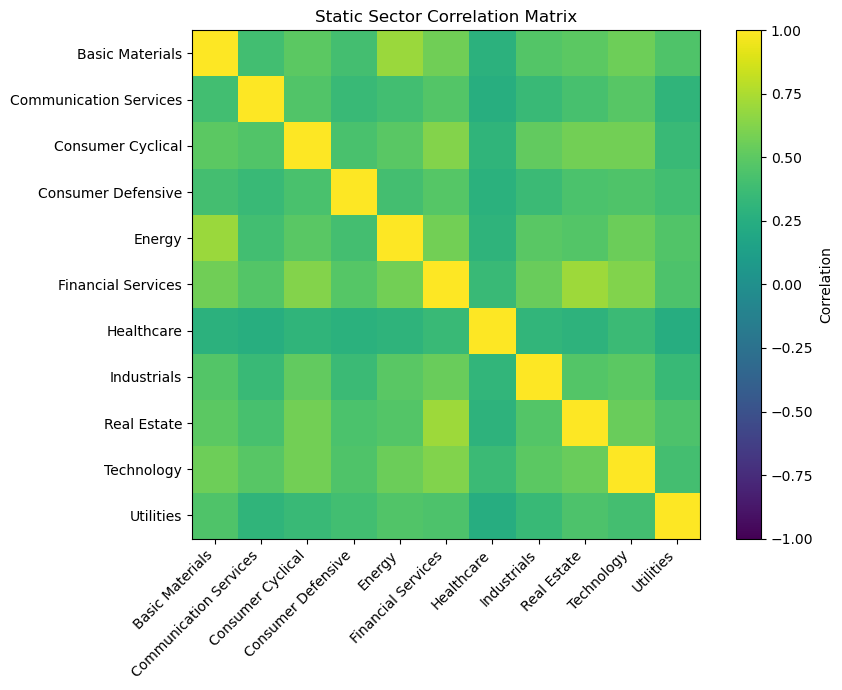

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,7))
plt.imshow(corr_static, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_static.columns)), corr_static.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_static.index)), corr_static.index)
plt.title("Static Sector Correlation Matrix")
plt.tight_layout()
plt.show()


Static Sector Correlation Structure
The heatmap shows the full-sample correlation matrix of daily sector returns.
Each value measures how strongly two sectors tend to move together over time.
Key observations:
Correlations are uniformly positive across all sector pairs.
This confirms that sector returns are primarily driven by common market-wide factors rather than independent idiosyncratic dynamics.
Economically related sectors exhibit the strongest co-movements.
Notable examples include:
Financial Services ↔ Real Estate (≈ 0.71)
Consumer Cyclical ↔ Financial Services (≈ 0.63)
Technology ↔ Consumer Cyclical (≈ 0.58)
These relationships reflect shared exposure to credit conditions, growth expectations, and the business cycle.
Defensive sectors show weaker correlations with the rest of the market.
Healthcare and Utilities consistently display lower correlation levels, highlighting their partial insulation from cyclical shocks.
No sector is truly independent.
Even the least correlated pairs remain positively correlated, indicating that diversification across sectors reduces risk but does not eliminate systemic exposure.
Implication:
This static view provides a baseline diversification map, but it masks important time-varying behavior. In particular, correlations are known to increase during market stress, motivating a dynamic analysis in the next phase.

# 7.Rolling sector correlations (time evolution)

In [27]:
import numpy as np
import pandas as pd

window = 60

avg_corr_60d = []

dates = sector_mat.index

for i in range(window - 1, len(sector_mat)):
    window_data = sector_mat.iloc[i - window + 1 : i + 1]
    C = window_data.corr()
    avg_corr = C.values[np.triu_indices_from(C, k=1)].mean()
    avg_corr_60d.append(avg_corr)

avg_corr_60d = pd.Series(
    avg_corr_60d,
    index=dates[window - 1 :],
    name="AvgCorrelation_60d"
)

avg_corr_60d.head()


Date
2005-03-31    0.306491
2005-04-01    0.288574
2005-04-04    0.283559
2005-04-05    0.282158
2005-04-06    0.284365
Name: AvgCorrelation_60d, dtype: float64

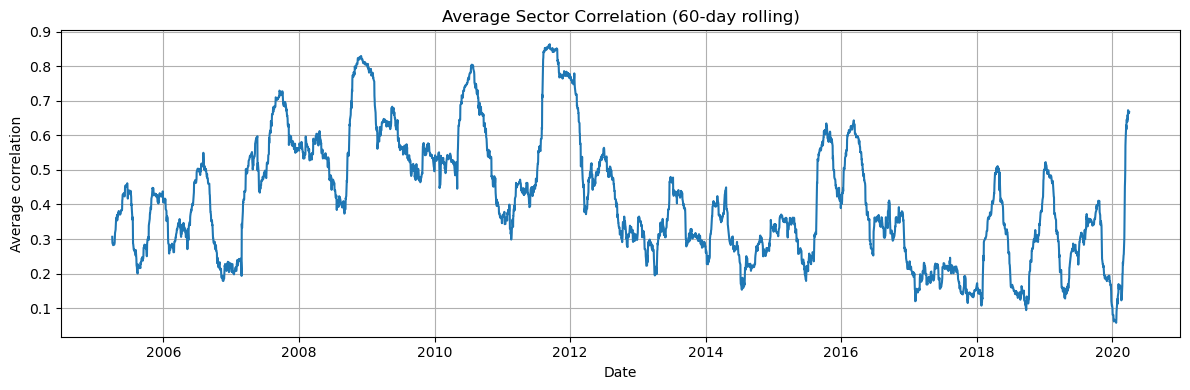

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(avg_corr_60d.index, avg_corr_60d.values)
plt.title("Average Sector Correlation (60-day rolling)")
plt.xlabel("Date")
plt.ylabel("Average correlation")
plt.grid(True)
plt.tight_layout()
plt.show()


Time-Varying Sector Correlation (60-Day Rolling Average)
This figure shows the 60-day rolling average correlation between all pairs of sector returns.
Each point summarizes how strongly sectors moved together over the preceding three months.
Key interpretations:
Sector correlations are highly time-varying.
The average correlation fluctuates between low values (≈ 0.15–0.30) and very high values (above 0.80), indicating that diversification benefits are not constant over time.
Correlation spikes coincide with market stress periods.
Large peaks appear around major crisis episodes (e.g., 2008–2009 and 2011–2012), when sector returns become strongly synchronized.
During these periods, sector-based diversification largely disappears.
Calm market regimes exhibit lower correlations.
Between crisis episodes, the average correlation drops substantially, reflecting more heterogeneous sector behavior and improved diversification potential.
Diversification is regime-dependent.
The same sector allocation can behave as well-diversified in normal times but become effectively one-dimensional during stressed markets.
Economic insight:
This dynamic confirms that systemic risk is primarily a correlation phenomenon, not a volatility one.
Understanding when correlations rise is therefore crucial for both risk management and predictive modeling.
Why this figure matters for the project
It justifies regime conditioning (SPY will enter next phases)
It motivates clustering based on correlations
It explains why static correlation matrices are insufficient
It creates a natural transition to market states & features

# 8.Regime-conditional sector performance

In [31]:
spy["Date"] = pd.to_datetime(spy["Date"])

spy_regimes = spy[["Date", "Regime"]].copy()

# if there are duplicates dates in spy, keep last (safest)
spy_regimes = spy_regimes.drop_duplicates(subset=["Date"], keep="last")

spy_regimes.head()


,Date,Regime
0,1993-01-29,Bull
1,1993-02-01,Bull
2,1993-02-02,Bull
3,1993-02-03,Bull
4,1993-02-04,Bull


In [32]:
sector_daily["Date"] = pd.to_datetime(sector_daily["Date"])
sector_daily.head()


,Date,Sector,SectorReturn,WeightSum,N
0,2005-01-04,Basic Materials,-0.025943,1.0,94.0
1,2005-01-04,Communication Services,-0.018059,1.0,60.0
2,2005-01-04,Consumer Cyclical,-0.011764,1.0,198.0
3,2005-01-04,Consumer Defensive,-0.017587,1.0,87.0
4,2005-01-04,Energy,-0.010518,1.0,84.0


In [33]:
sector_regime_df = sector_daily.merge(
    spy_regimes,
    on="Date",
    how="inner"
)

sector_regime_df = sector_regime_df.sort_values(["Date", "Sector"]).reset_index(drop=True)
sector_regime_df.head(10)


,Date,Sector,SectorReturn,WeightSum,N,Regime
0,2005-01-04,Basic Materials,-0.025943,1.000000,94.0,Neutral
1,2005-01-04,Communication Services,-0.018059,1.000000,60.0,Neutral
2,2005-01-04,Consumer Cyclical,-0.011764,1.000000,198.0,Neutral
3,2005-01-04,Consumer Defensive,-0.017587,1.000000,87.0,Neutral
4,2005-01-04,Energy,-0.010518,1.000000,84.0,Neutral
5,2005-01-04,Financial Services,-0.011262,1.000000,517.0,Neutral
6,2005-01-04,Healthcare,-0.009249,0.999506,198.0,Neutral
7,2005-01-04,Industrials,-0.022945,0.999999,241.0,Neutral
8,2005-01-04,Real Estate,-0.014109,1.000000,88.0,Neutral
9,2005-01-04,Technology,-0.015982,0.999743,233.0,Neutral


In [34]:
sector_regime_df.isna().sum()


Date            0
Sector          0
SectorReturn    0
WeightSum       0
N               0
Regime          0
dtype: int64

In [35]:
days_per_regime = sector_regime_df.groupby("Regime")["Date"].nunique().sort_values(ascending=False)
days_per_regime


Regime
Bull       2009
Neutral    1295
Bear        533
Name: Date, dtype: int64

In [36]:
sectors_per_regime = sector_regime_df.groupby("Regime")["Sector"].nunique()
sectors_per_regime


Regime
Bear       11
Bull       11
Neutral    11
Name: Sector, dtype: int64

In [37]:
coverage_ok = (pd.crosstab(sector_regime_df["Sector"], sector_regime_df["Regime"]) > 0).all(axis=1)
coverage_ok.value_counts()


True    11
Name: count, dtype: int64

# 8.1. Boxplot (SectorReturn by Regime)

In [38]:
regime_order = ["Bear", "Neutral", "Bull"]
sector_regime_df["Regime"] = pd.Categorical(sector_regime_df["Regime"], categories=regime_order, ordered=True)


<Figure size 1000x500 with 0 Axes>

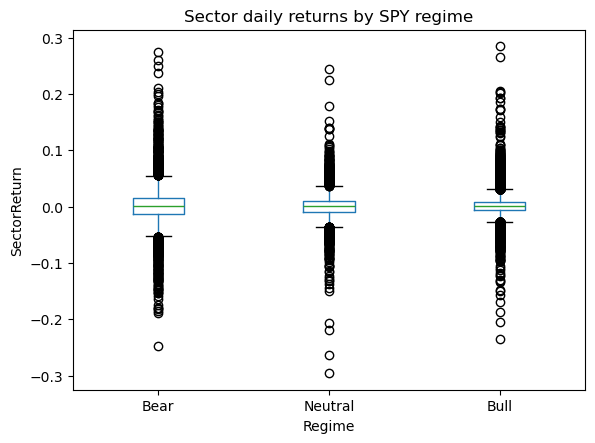

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
sector_regime_df.boxplot(column="SectorReturn", by="Regime", grid=False)
plt.title("Sector daily returns by SPY regime")
plt.suptitle("")  # removes pandas default subtitle
plt.xlabel("Regime")
plt.ylabel("SectorReturn")
plt.show()


Interpretation of the boxplot (what it tells us)
🔹 Median returns (central line)
Bull regime: median is clearly positive
Neutral regime: median is around zero
Bear regime: median is slightly negative
👉 This confirms the regime labeling is economically meaningful:
Bull ≠ Bear, not just labels
Sector returns react differently depending on regime
🔹 Dispersion (box + whiskers)
Bear regime has the widest spread
Bull regime also volatile, but skewed upward
Neutral regime is the tightest
👉 Interpretation:
Bear markets amplify risk and dispersion across sectors
Neutral regimes are calmer and more homogeneous
Bull markets reward risk, but still show dispersion
🔹 Outliers (black dots)
Extreme negative outliers are most frequent in Bear
Extreme positive outliers dominate in Bull
👉 This suggests:
Crashes cluster in bear regimes
Explosive gains cluster in bull regimes
Regimes are asymmetric, not just shifted means
🧠 One-sentence takeaway (very important for your story)
Market regimes strongly condition both the level and the dispersion of sector returns, validating the use of regime-aware analysis before studying sector relationships.

# 8.2.Bar plot: best / worst sectors per regime

In [40]:
avg_returns = (
    sector_regime_df
    .groupby(["Regime", "Sector"])["SectorReturn"]
    .mean()
    .reset_index()
)
avg_returns.head()


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_72829/1507491175.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["Regime", "Sector"])["SectorReturn"]


,Regime,Sector,SectorReturn
0,Bear,Basic Materials,0.001272
1,Bear,Communication Services,0.001808
2,Bear,Consumer Cyclical,0.002777
3,Bear,Consumer Defensive,-0.000177
4,Bear,Energy,0.000821


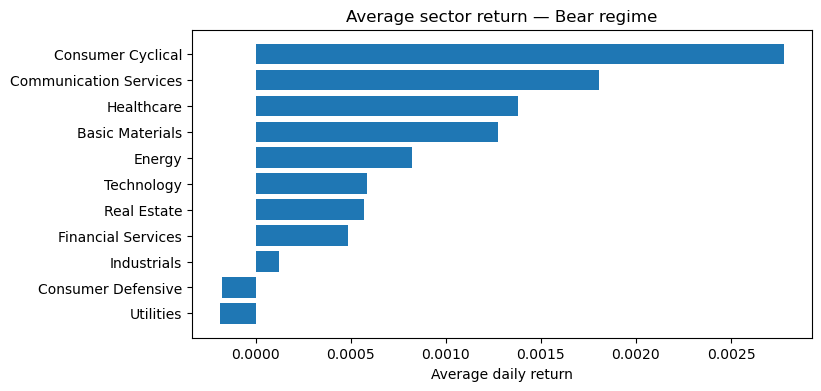

In [41]:
import matplotlib.pyplot as plt

bear_data = avg_returns[avg_returns["Regime"] == "Bear"].sort_values("SectorReturn")

plt.figure(figsize=(8, 4))
plt.barh(bear_data["Sector"], bear_data["SectorReturn"])
plt.title("Average sector return — Bear regime")
plt.xlabel("Average daily return")
plt.show()


Interpretation — Bear regime (what this REALLY says)
🔹 Overall picture
Even in bear regimes, not all sectors perform equally:
Some sectors still deliver positive average returns
Others are flat or slightly negative
👉 This already breaks the naïve idea that “everything goes down in bear markets”.
Interpretation:
Bear markets are not uniform crashes
Certain sectors can benefit from rotations, pricing power, or structural demand
Healthcare behaving well is intuitive (defensive demand)
Cyclicals performing well suggests rebound phases inside bears or regime definition capturing drawdown, not trend
This is actually a very interesting result.
🔹 Worst performers in Bear regimes
Utilities
Consumer Defensive
Industrials
This is counter-intuitive (defensives expected to protect).
👉 Possible explanation (important for your story):
These are average daily returns, not cumulative
Defensive sectors may fall less, but still drift slightly negative
Volatility + regime definition matters
This gives you something to discuss, which is GOOD.
🧠 Key takeaway sentence (write this down)
Bear regimes are characterized by strong sector heterogeneity: while traditional defensive sectors do not systematically outperform, certain cyclical and communication-driven sectors show positive average returns.

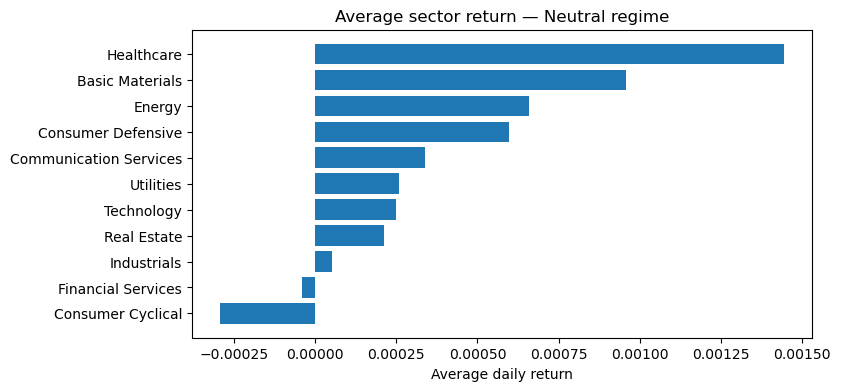

In [42]:
neutral_data = avg_returns[avg_returns["Regime"] == "Neutral"].sort_values("SectorReturn")

plt.figure(figsize=(8, 4))
plt.barh(neutral_data["Sector"], neutral_data["SectorReturn"])
plt.title("Average sector return — Neutral regime")
plt.xlabel("Average daily return")
plt.show()


Interpretation — Neutral regime
What we see
Healthcare is clearly the top performer
Basic Materials and Energy also perform well
Consumer Defensive and Utilities are positive but moderate
Consumer Cyclical is the only clearly negative sector
Interpretation
Neutral regimes favor structural demand sectors (healthcare, materials)
Risk-taking is selective, not broad
Cyclical consumption underperforms when momentum is weak
Key takeaway
In neutral markets, returns concentrate in structurally resilient sectors, while cyclicals already start to lag.

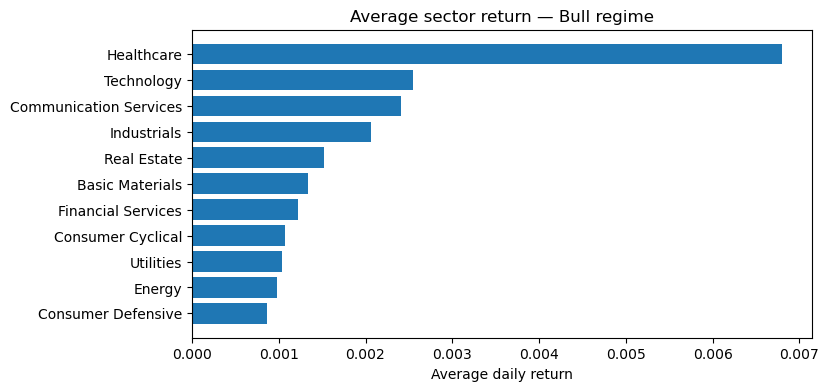

In [43]:
bull_data = avg_returns[avg_returns["Regime"] == "Bull"].sort_values("SectorReturn")

plt.figure(figsize=(8, 4))
plt.barh(bull_data["Sector"], bull_data["SectorReturn"])
plt.title("Average sector return — Bull regime")
plt.xlabel("Average daily return")
plt.show()


Interpretation — Bull regime
What we see
All sectors have positive average returns
Healthcare surprisingly dominates
Technology and Communication Services strongly benefit
Cyclicals and financials perform well but are not top leaders
Defensive sectors remain positive but lag
Interpretation
Bull markets lift all boats, but not equally
Growth-oriented and innovation-driven sectors benefit most
Defensive sectors lose relative attractiveness, not absolute performance
Key takeaway
Bull regimes amplify cross-sector dispersion, rewarding growth and innovation sectors disproportionately.

Comparison across the three regimes (VERY IMPORTANT)
🔁 Sector ranking stability
Healthcare performs well in all regimes → regime-robust sector
Technology & Communication strongly improve from Neutral → Bull
Consumer Cyclical:
Strong in Bear
Worst in Neutral
Mid-tier in Bull
👉 Rankings change substantially across regimes
🔁 Dispersion across regimes
Bear: high dispersion, asymmetric risk
Neutral: concentrated leadership
Bull: broad gains, but with clear winners
👉 This confirms regimes are not just shifts in mean, but structural reorganizations of sector behavior.
🧠 Core narrative sentence (gold)
Market regimes reshape both sector performance and sector hierarchy, justifying regime-conditional analysis rather than unconditional averages.

# 8.3 Clustering By Regime

In [44]:
bear_df = sector_regime_df[sector_regime_df["Regime"] == "Bear"].copy()

bear_df.head()


,Date,Sector,SectorReturn,WeightSum,N,Regime
803,2005-04-20,Basic Materials,-0.014686,1.0,95.0,Bear
804,2005-04-20,Communication Services,-0.000196,1.0,61.0,Bear
805,2005-04-20,Consumer Cyclical,-0.003056,1.0,198.0,Bear
806,2005-04-20,Consumer Defensive,-0.012208,1.0,88.0,Bear
807,2005-04-20,Energy,-0.016627,1.0,86.0,Bear


In [45]:
bear_pivot = bear_df.pivot(
    index="Date",
    columns="Sector",
    values="SectorReturn"
)

bear_pivot.head()


Sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Date,,,,,,,,,,,
2005-04-20,-0.014686,-0.000196,-0.003056,-0.012208,-0.016627,-0.015421,0.005456,-0.013270,-0.005161,-0.015053,-0.009743
2008-07-14,0.010653,-0.014334,-0.006953,-0.003432,0.006833,-0.054604,-0.005482,-0.002076,-0.027022,-0.007039,-0.010279
2008-07-15,-0.016529,-0.010158,-0.008997,-0.003939,-0.029238,-0.031067,0.013053,-0.020220,-0.004849,-0.003617,-0.008338
2008-09-09,-0.090952,-0.046067,-0.038144,-0.014810,-0.077900,-0.057648,-0.019215,-0.034944,-0.037917,-0.029167,-0.043824
2008-09-15,-0.085016,-0.058321,-0.032994,-0.021876,-0.084348,-0.075354,-0.023897,-0.040968,-0.079766,-0.049772,-0.035372


In [46]:
bear_pivot.shape


(533, 11)

In [47]:
bear_pivot.isna().mean().sort_values(ascending=False)


Sector
Basic Materials           0.0
Communication Services    0.0
Consumer Cyclical         0.0
Consumer Defensive        0.0
Energy                    0.0
Financial Services        0.0
Healthcare                0.0
Industrials               0.0
Real Estate               0.0
Technology                0.0
Utilities                 0.0
dtype: float64

In [48]:
bear_corr = bear_pivot.corr()

bear_corr


Sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Sector,,,,,,,,,,,
Basic Materials,1.000000,0.548278,0.748489,0.704664,0.787688,0.691770,0.623406,0.757736,0.655451,0.798492,0.740451
Communication Services,0.548278,1.000000,0.587958,0.565737,0.537512,0.527546,0.488298,0.566240,0.521438,0.615939,0.542819
Consumer Cyclical,0.748489,0.587958,1.000000,0.716049,0.698149,0.770600,0.583364,0.830940,0.758005,0.812304,0.642524
Consumer Defensive,0.704664,0.565737,0.716049,1.000000,0.715964,0.694777,0.698043,0.741670,0.684572,0.780536,0.772985
Energy,0.787688,0.537512,0.698149,0.715964,1.000000,0.685066,0.654515,0.762947,0.634948,0.767556,0.751323
Financial Services,0.691770,0.527546,0.770600,0.694777,0.685066,1.000000,0.624527,0.773626,0.821324,0.771834,0.654364
Healthcare,0.623406,0.488298,0.583364,0.698043,0.654515,0.624527,1.000000,0.622988,0.579557,0.683675,0.678093
Industrials,0.757736,0.566240,0.830940,0.741670,0.762947,0.773626,0.622988,1.000000,0.741172,0.808593,0.741557
Real Estate,0.655451,0.521438,0.758005,0.684572,0.634948,0.821324,0.579557,0.741172,1.000000,0.746884,0.623456


In bear regimes, sector returns are strongly correlated (mostly 0.5–0.8), suggesting increased market-wide coupling during stress periods.
This already motivates clustering

In [49]:
bear_corr.describe()


Sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
count,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000
mean,0.732402,0.591070,0.740762,0.734091,0.726879,0.728676,0.657861,0.758861,0.706073,0.777101,0.719079
std,0.115811,0.139851,0.119123,0.104688,0.115796,0.122097,0.127948,0.110691,0.130490,0.093988,0.117316
min,0.548278,0.488298,0.583364,0.565737,0.537512,0.527546,0.488298,0.566240,0.521438,0.615939,0.542819
25%,0.673611,0.532529,0.670337,0.696410,0.669791,0.669715,0.603176,0.741364,0.629202,0.754589,0.648444
50%,0.740451,0.548278,0.748489,0.715964,0.715964,0.694777,0.624527,0.757736,0.684572,0.771834,0.740451
75%,0.772712,0.577099,0.791452,0.757328,0.765251,0.772730,0.680884,0.791109,0.752445,0.803542,0.756809
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [50]:
from scipy.spatial.distance import squareform

bear_dist = 1 - bear_corr


In [51]:
bear_dist_condensed = squareform(bear_dist.values)


In [52]:
from scipy.cluster.hierarchy import linkage

bear_linkage = linkage(bear_dist_condensed, method="average")


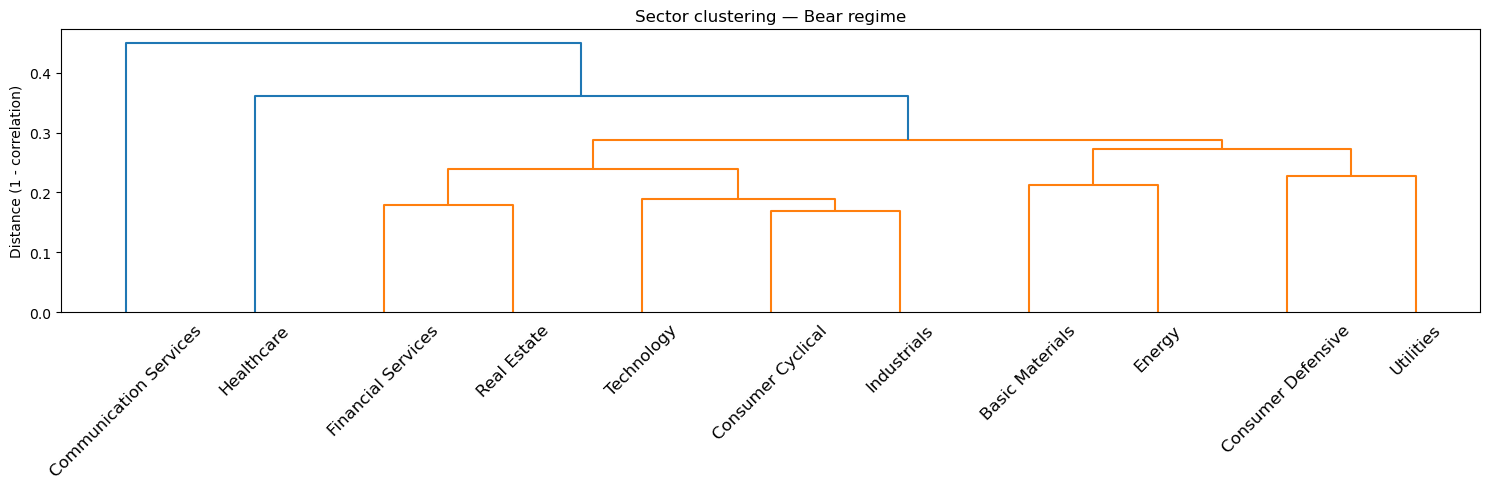

In [54]:
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
dendrogram(
    bear_linkage,
    labels=bear_corr.index.tolist(),
    leaf_rotation=45
)
plt.title("Sector clustering — Bear regime")
plt.ylabel("Distance (1 - correlation)")
plt.tight_layout()
plt.show()


In [55]:
from scipy.cluster.hierarchy import leaves_list

# Get order of sectors from clustering
sector_order = leaves_list(bear_linkage)

# Reorder correlation matrix
bear_corr_clustered = bear_corr.iloc[sector_order, sector_order]

bear_corr_clustered


Sector,Communication Services,Healthcare,Financial Services,Real Estate,Technology,Consumer Cyclical,Industrials,Basic Materials,Energy,Consumer Defensive,Utilities
Sector,,,,,,,,,,,
Communication Services,1.000000,0.488298,0.527546,0.521438,0.615939,0.587958,0.566240,0.548278,0.537512,0.565737,0.542819
Healthcare,0.488298,1.000000,0.624527,0.579557,0.683675,0.583364,0.622988,0.623406,0.654515,0.698043,0.678093
Financial Services,0.527546,0.624527,1.000000,0.821324,0.771834,0.770600,0.773626,0.691770,0.685066,0.694777,0.654364
Real Estate,0.521438,0.579557,0.821324,1.000000,0.746884,0.758005,0.741172,0.655451,0.634948,0.684572,0.623456
Technology,0.615939,0.683675,0.771834,0.746884,1.000000,0.812304,0.808593,0.798492,0.767556,0.780536,0.762295
Consumer Cyclical,0.587958,0.583364,0.770600,0.758005,0.812304,1.000000,0.830940,0.748489,0.698149,0.716049,0.642524
Industrials,0.566240,0.622988,0.773626,0.741172,0.808593,0.830940,1.000000,0.757736,0.762947,0.741670,0.741557
Basic Materials,0.548278,0.623406,0.691770,0.655451,0.798492,0.748489,0.757736,1.000000,0.787688,0.704664,0.740451
Energy,0.537512,0.654515,0.685066,0.634948,0.767556,0.698149,0.762947,0.787688,1.000000,0.715964,0.751323


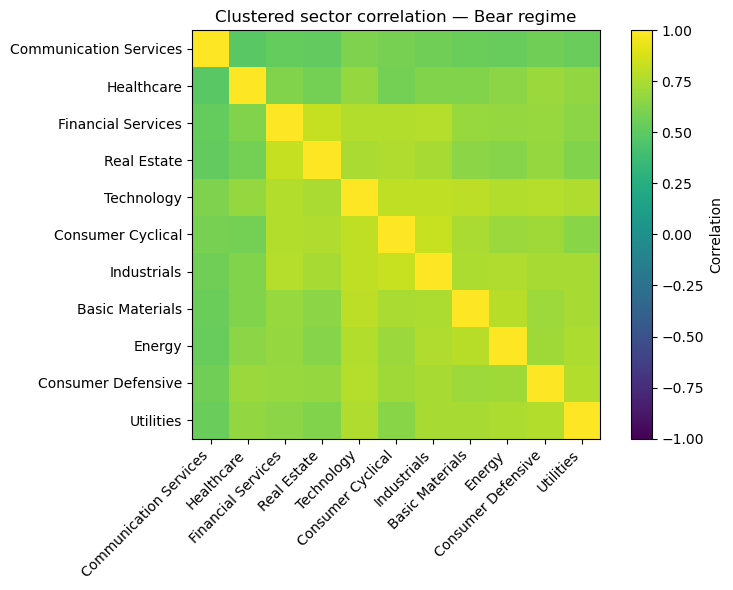

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(bear_corr_clustered, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    ticks=range(len(bear_corr_clustered.columns)),
    labels=bear_corr_clustered.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=range(len(bear_corr_clustered.index)),
    labels=bear_corr_clustered.index
)

plt.title("Clustered sector correlation — Bear regime")
plt.tight_layout()
plt.show()


In [57]:
neutral_df = sector_regime_df[sector_regime_df["Regime"] == "Neutral"].copy()
neutral_df.head()


,Date,Sector,SectorReturn,WeightSum,N,Regime
0,2005-01-04,Basic Materials,-0.025943,1.0,94.0,Neutral
1,2005-01-04,Communication Services,-0.018059,1.0,60.0,Neutral
2,2005-01-04,Consumer Cyclical,-0.011764,1.0,198.0,Neutral
3,2005-01-04,Consumer Defensive,-0.017587,1.0,87.0,Neutral
4,2005-01-04,Energy,-0.010518,1.0,84.0,Neutral


In [58]:
neutral_pivot = neutral_df.pivot(
    index="Date",
    columns="Sector",
    values="SectorReturn"
)

neutral_pivot.shape


(1295, 11)

In [59]:
neutral_corr = neutral_pivot.corr()
neutral_corr


Sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Sector,,,,,,,,,,,
Basic Materials,1.000000,0.401953,0.488870,0.356984,0.731697,0.532766,0.320468,0.548701,0.484661,0.552408,0.346286
Communication Services,0.401953,1.000000,0.499419,0.387137,0.399260,0.470531,0.263438,0.437250,0.444418,0.522232,0.245380
Consumer Cyclical,0.488870,0.499419,1.000000,0.466454,0.496398,0.700140,0.386263,0.614466,0.689985,0.621863,0.323555
Consumer Defensive,0.356984,0.387137,0.466454,1.000000,0.350693,0.479786,0.281203,0.425377,0.465925,0.463612,0.285425
Energy,0.731697,0.399260,0.496398,0.350693,1.000000,0.546721,0.318036,0.580137,0.503671,0.557058,0.385433
Financial Services,0.532766,0.470531,0.700140,0.479786,0.546721,1.000000,0.387384,0.647063,0.758755,0.622713,0.368520
Healthcare,0.320468,0.263438,0.386263,0.281203,0.318036,0.387384,1.000000,0.361382,0.373237,0.412544,0.177045
Industrials,0.548701,0.437250,0.614466,0.425377,0.580137,0.647063,0.361382,1.000000,0.590671,0.605980,0.333526
Real Estate,0.484661,0.444418,0.689985,0.465925,0.503671,0.758755,0.373237,0.590671,1.000000,0.574901,0.412300


In [60]:
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, leaves_list

neutral_dist = 1 - neutral_corr
neutral_dist_condensed = squareform(neutral_dist.values)

neutral_linkage = linkage(neutral_dist_condensed, method="average")


In [61]:
neutral_order = leaves_list(neutral_linkage)
neutral_corr_clustered = neutral_corr.iloc[neutral_order, neutral_order]


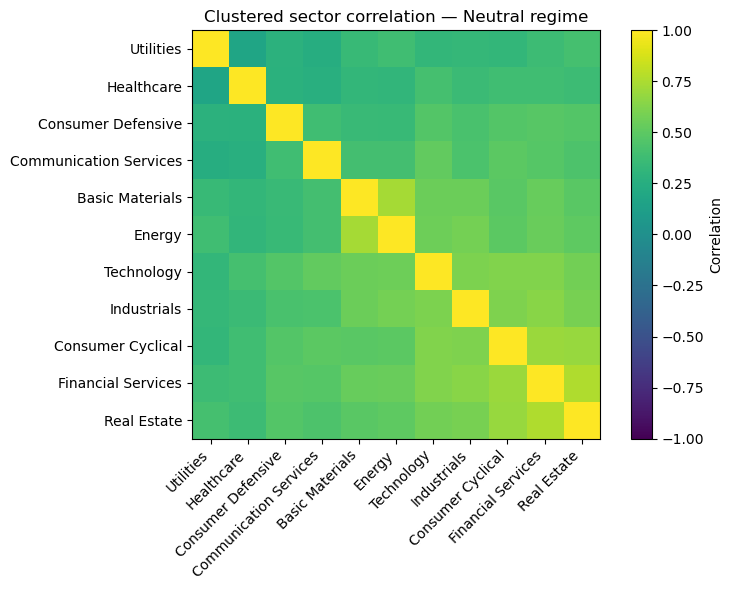

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(neutral_corr_clustered, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    ticks=range(len(neutral_corr_clustered.columns)),
    labels=neutral_corr_clustered.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=range(len(neutral_corr_clustered.index)),
    labels=neutral_corr_clustered.index
)

plt.title("Clustered sector correlation — Neutral regime")
plt.tight_layout()
plt.show()


In [63]:
bull_df = sector_regime_df[sector_regime_df["Regime"] == "Bull"].copy()
bull_df.head()


,Date,Sector,SectorReturn,WeightSum,N,Regime
4708,2006-09-15,Basic Materials,0.001818,1.000000,109.0,Bull
4709,2006-09-15,Communication Services,0.009283,1.000000,66.0,Bull
4710,2006-09-15,Consumer Cyclical,-0.034202,1.000000,211.0,Bull
4711,2006-09-15,Consumer Defensive,-0.007616,0.988885,91.0,Bull
4712,2006-09-15,Energy,-0.001210,1.000000,94.0,Bull


In [64]:
bull_pivot = bull_df.pivot(
    index="Date",
    columns="Sector",
    values="SectorReturn"
)

bull_pivot.shape


(2009, 11)

In [65]:
bull_corr = bull_pivot.corr()
bull_corr


Sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
Sector,,,,,,,,,,,
Basic Materials,1.000000,0.191456,0.227717,0.225494,0.554073,0.396682,0.116207,0.200969,0.246194,0.320221,0.247818
Communication Services,0.191456,1.000000,0.263129,0.156118,0.221444,0.338605,0.137061,0.146231,0.217046,0.288588,0.109739
Consumer Cyclical,0.227717,0.263129,1.000000,0.193251,0.255034,0.364055,0.157856,0.249725,0.207808,0.314476,0.118569
Consumer Defensive,0.225494,0.156118,0.193251,1.000000,0.223731,0.283687,0.122106,0.136416,0.227448,0.205823,0.236417
Energy,0.554073,0.221444,0.255034,0.223731,1.000000,0.460180,0.133829,0.242551,0.180513,0.320281,0.230990
Financial Services,0.396682,0.338605,0.364055,0.283687,0.460180,1.000000,0.218529,0.288763,0.275178,0.435480,0.224349
Healthcare,0.116207,0.137061,0.157856,0.122106,0.133829,0.218529,1.000000,0.184538,0.105240,0.197932,0.094894
Industrials,0.200969,0.146231,0.249725,0.136416,0.242551,0.288763,0.184538,1.000000,0.119919,0.220883,0.093123
Real Estate,0.246194,0.217046,0.207808,0.227448,0.180513,0.275178,0.105240,0.119919,1.000000,0.250823,0.255270


In [66]:
bull_dist = 1 - bull_corr
bull_dist_condensed = squareform(bull_dist.values)

bull_linkage = linkage(bull_dist_condensed, method="average")


In [67]:
bull_order = leaves_list(bull_linkage)
bull_corr_clustered = bull_corr.iloc[bull_order, bull_order]


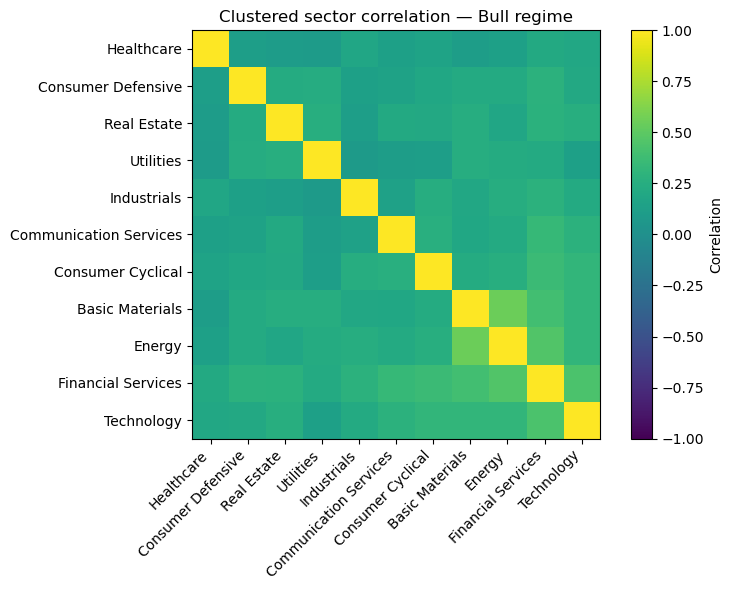

In [68]:
plt.figure(figsize=(8, 6))
plt.imshow(bull_corr_clustered, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    ticks=range(len(bull_corr_clustered.columns)),
    labels=bull_corr_clustered.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=range(len(bull_corr_clustered.index)),
    labels=bull_corr_clustered.index
)

plt.title("Clustered sector correlation — Bull regime")
plt.tight_layout()
plt.show()


Interpretation — Bear regime
What stands out
Very high correlations everywhere (mostly yellow / light green)
Large single dominant block
Defensive sectors (Utilities, Consumer Defensive) are not isolated
Cyclical, tech, financials all move together
Interpretation
In bear markets, systemic risk dominates
Sector identities blur → “everything sells together”
Diversification across sectors breaks down
Key sentence
Bear regimes are characterized by strong market-wide coupling, where sector diversification provides limited protection.
Interpretation — Neutral regime
What stands out
Correlations are lower and more heterogeneous
Clear sub-clusters appear
Defensive sectors (Utilities, Consumer Defensive, Healthcare) are closer together
Cyclicals and financials form a different block
Interpretation
Neutral regimes allow sector differentiation
Market is no longer driven by a single dominant factor
Sector-based allocation starts to matter again
Key sentence
In neutral regimes, sector structure re-emerges, allowing meaningful diversification across economic profiles.
Interpretation — Bull regime
What stands out
Correlations are moderate, lower than Bear
Clusters are less tight than Neutral
Growth sectors (Technology, Financials, Energy) show strong internal coherence
Defensive sectors drift toward the rest of the market
Interpretation
Bull markets reward risk-taking
Sectors rise together, but not as synchronised as in bears
Correlation increases again, but without panic-driven coupling
Key sentence
Bull regimes display broad participation with moderate correlation, reflecting optimistic but selective risk appetite.
Interpretation — Bull regime
What stands out
Correlations are moderate, lower than Bear
Clusters are less tight than Neutral
Growth sectors (Technology, Financials, Energy) show strong internal coherence
Defensive sectors drift toward the rest of the market
Interpretation
Bull markets reward risk-taking
Sectors rise together, but not as synchronised as in bears
Correlation increases again, but without panic-driven coupling
Key sentence
Bull regimes display broad participation with moderate correlation, reflecting optimistic but selective risk appetite.